In [1]:
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), "../.."))
# Add the main directory to sys.path
sys.path.append(main_dir)
import numpy as np

x = np.linspace(0, 1, 20)
y = np.linspace(0, 1, 20)
dx = x[-1]-x[-2]
dy = y[-1]-y[-2]

Cartesianstack = None
for i in range(len(x)):
    for j in range(len(y)):
        cartesian = np.array((x[i], y[j]))
        cartesian = np.reshape(cartesian, (1, 2)) 
        if Cartesianstack is None:
            Cartesianstack=cartesian
        else:
            Cartesianstack = np.concatenate([Cartesianstack, cartesian]) 

# Extract frontier points
frontier_mask = (Cartesianstack[:, 0] == 0) | (Cartesianstack[:, 0] == 1) | (Cartesianstack[:, 1] == 0) | (Cartesianstack[:, 1] == 1)
### Crear datos para fijar evidencias en proceso gaussiano
X_init = Cartesianstack[frontier_mask]
Y_init = np.zeros((len(X_init), 1))
init_data = (X_init, Y_init)

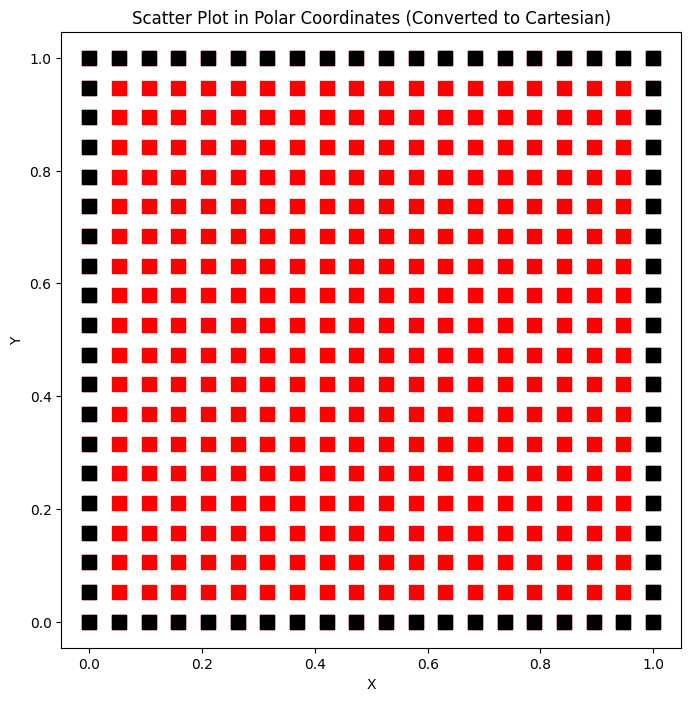

In [2]:
import matplotlib.pyplot as plt
# Plot the scatter plot
plt.figure(figsize=(8, 8))
#plt.scatter(x_flat, y_flat, c='red')
plt.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c='red', s=100, marker='s')
plt.scatter(X_init[:, 0], X_init[:, 1], c='k', s=100, marker='s')
plt.title("Scatter Plot in Polar Coordinates (Converted to Cartesian)")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis('equal');  # Ensure the aspect ratio is equal

In [3]:
from Box_functions import *
nxs = [1,2,3]
for n1 in nxs:
    valoresquehatomadon2 = []
    for n2 in nxs:
        valoresquehatomadon2.append(n2)
        if n2!=n1 and n1 in valoresquehatomadon2:
            break
        else:
            print(f'Energía de estado {n1, n2}:', Enxny(n1, n2))

Energía de estado (1, 1): 9.869604401089358
Energía de estado (2, 1): 24.674011002723397
Energía de estado (2, 2): 39.47841760435743
Energía de estado (3, 1): 49.34802200544679
Energía de estado (3, 2): 64.15242860708082
Energía de estado (3, 3): 88.82643960980423


In [4]:
THPsi0flat, THPsi0, THEintegrando = Psinxny(1,1, x=x, y=y, dx=dx, dy=dy)
THPsi1flat, THPsi1, THE1integrando = Psinxny(1,2,x=x, y=y, dx=dx, dy=dy)
THPsi12flat, THPsi12, THE12integrando = Psinxny(2,1,x=x, y=y, dx=dx, dy=dy)
THPsi2flat, THPsi2, THE2integrando = Psinxny(2, 2, x=x, y=y, dx=dx, dy=dy)
THPsi3flat, THPsi3, THE3integrando = Psinxny(3, 1, x=x, y=y, dx=dx, dy=dy)
THPsi31flat, THPsi31, THE31integrando = Psinxny(1, 3, x=x, y=y, dx=dx, dy=dy)

In [5]:
GPx = np.linspace(0, 1, 32)
GPy = np.linspace(0, 1, 32)
dGPx = GPx[-1] - GPx[-2]
dGPy = GPy[-1] - GPy[-2]
GPstack = None
for i in range(len(GPx)):
    for j in range(len(GPy)):
        cartesian = np.array((GPx[i], GPy[j]))
        cartesian = np.reshape(cartesian, (1, 2)) 
        if GPstack is None:
            GPstack=cartesian
        else:
            GPstack = np.concatenate([GPstack, cartesian]) 

GPTHPsi0flat, GPTHPsi0, GPTHEintegrando = Psinxny(1,1, x=GPx, y=GPy, dx=dGPx, dy=dGPy)
GPTHPsi1flat, GPTHPsi1, GPTHE1integrando = Psinxny(1,2,x=GPx, y=GPy, dx=dGPx, dy=dGPy)
GPTHPsi12flat, GPTHPsi12, GPTHE12integrando = Psinxny(2,1,x=GPx, y=GPy, dx=dGPx, dy=dGPy)
GPTHPsi2flat, GPTHPsi2, GPTHE2integrando = Psinxny(2, 2, x=GPx, y=GPy, dx=dGPx, dy=dGPy)
GPTHPsi3flat, GPTHPsi3, GPTHE3integrando = Psinxny(3, 1, x=GPx, y=GPy, dx=dGPx, dy=dGPy)
GPTHPsi31flat, GPTHPsi31, GPTHE31integrando = Psinxny(1, 3, x=GPx, y=GPy, dx=dGPx, dy=dGPy)

In [6]:
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), "../.."))
# Add the main directory to sys.path
sys.path.append(main_dir)

# importing
from OptFunctions.TwoDBox import *
from TwoD_EGPA import *
print(f'Función de coste de estado teórico: {TwoDBox(Psi=THPsi0, dx=dx, dy=dy)} \ntendrá que ser la energía del estado al cuadrado {Enxny(1,1), Enxny(1,1)**2} teórica,\npero el valor esperado de la energía del estado teórico es {THEintegrando}')
print(f'\n\nPara el primer estado excitado (1, 2)\nEl valor del estado teórico en la función de coste excitada es {TwoDBoxExc1(Psi=THPsi1, Psi0=THPsi0, E0=Enxny(1,1), dx=dx, dy=dy)},\nque debería ser la diferencia entre las energías de los niveles al cuadrado {(Enxny(1,2)-Enxny(1,1))**2} \no usando valores integrados {(THE1integrando-THEintegrando)**2}')

Función de coste de estado teórico: 95.64816279671992 
tendrá que ser la energía del estado al cuadrado (9.869604401089358, 97.40909103400243) teórica,
pero el valor esperado de la energía del estado teórico es 9.779987873035443


Para el primer estado excitado (1, 2)
El valor del estado teórico en la función de coste excitada es 197.41538581382608,
que debería ser la diferencia entre las energías de los niveles al cuadrado 219.1704548265055 
o usando valores integrados 199.94172356378408


# Estado 1 1

In [7]:
import sys
import os
# Get the absolute path of the main directory
main_dir = os.path.abspath(os.path.join(os.getcwd(), "../.."))
# Add the main directory to sys.path
sys.path.append(main_dir)

# importing
from OptFunctions.TwoDBox import *
from TwoD_EGPA import *
import warnings
warnings.filterwarnings('ignore')

params = {}
params['dx'] = dx
params['dy'] = dy
print(f'La función de coste debería ser el cuadrado de la energía. \nCon fórmula:{Enxny(1,1)**2}, con estado teórico discretizado: {(THEintegrando)**2}')
print(f'Función de coste para energía teórica discreta F={TwoDBox(Psi=THPsi0, dx=dx, dy=dy)}')
# Gaussian = TwoD_EGPA(size_gen=1000, grid_x=x, grid_y=y, max_iter=100, dead_iter=70, alpha=0.01, elite_factor=0.006, init_kernels=10, std_lower_bound=0.1 ,parallelize=True,init_data=init_data, normalize_solutions=True)
# egparesultground = Gaussian.minimize(TwoDBox, params, exp_from = 300, output_runtime=True)

while True:
    try: #values of alpha=0.01, elite = 0,006 with 1000 individuals
        Gaussian = TwoD_EGPA(size_gen=1000, grid_x=x, grid_y=y, max_iter=200, dead_iter=120, alpha=0.01, elite_factor=0.006, init_kernels=10, std_lower_bound=0.1 ,parallelize=True,init_data=init_data, normalize_solutions=True)
        egparesultground = Gaussian.minimize(TwoDBox, params, exp_from = 300, output_runtime=True)
        break
    except:
        print('Error fiteando el Kernel. Reiniciando algoritmo...\n\n')
        continue 

La función de coste debería ser el cuadrado de la energía. 
Con fórmula:97.40909103400243, con estado teórico discretizado: 95.64816279672033
Función de coste para energía teórica discreta F=95.64816279671992
IT:  0 	Best cost:  97.79232554322203
IT:  1 	Best cost:  97.79232554322203
IT:  2 	Best cost:  97.79232554322203
IT:  3 	Best cost:  97.79232554322203
IT:  4 	Best cost:  97.79232554322203
IT:  5 	Best cost:  97.79232554322203
IT:  6 	Best cost:  97.79232554322203
IT:  7 	Best cost:  97.79232554322203
IT:  8 	Best cost:  97.79232554322203
IT:  9 	Best cost:  97.79232554322203
IT:  10 	Best cost:  97.79232554322203
IT:  11 	Best cost:  97.79232554322203
IT:  12 	Best cost:  97.79232554322203
IT:  13 	Best cost:  97.79232554322203
IT:  14 	Best cost:  97.79232554322203
IT:  15 	Best cost:  97.79232554322203
IT:  16 	Best cost:  97.79232554322203
IT:  17 	Best cost:  97.79232554322203
IT:  18 	Best cost:  97.79232554322203
IT:  19 	Best cost:  97.79232554322203
IT:  20 	Best cost:  

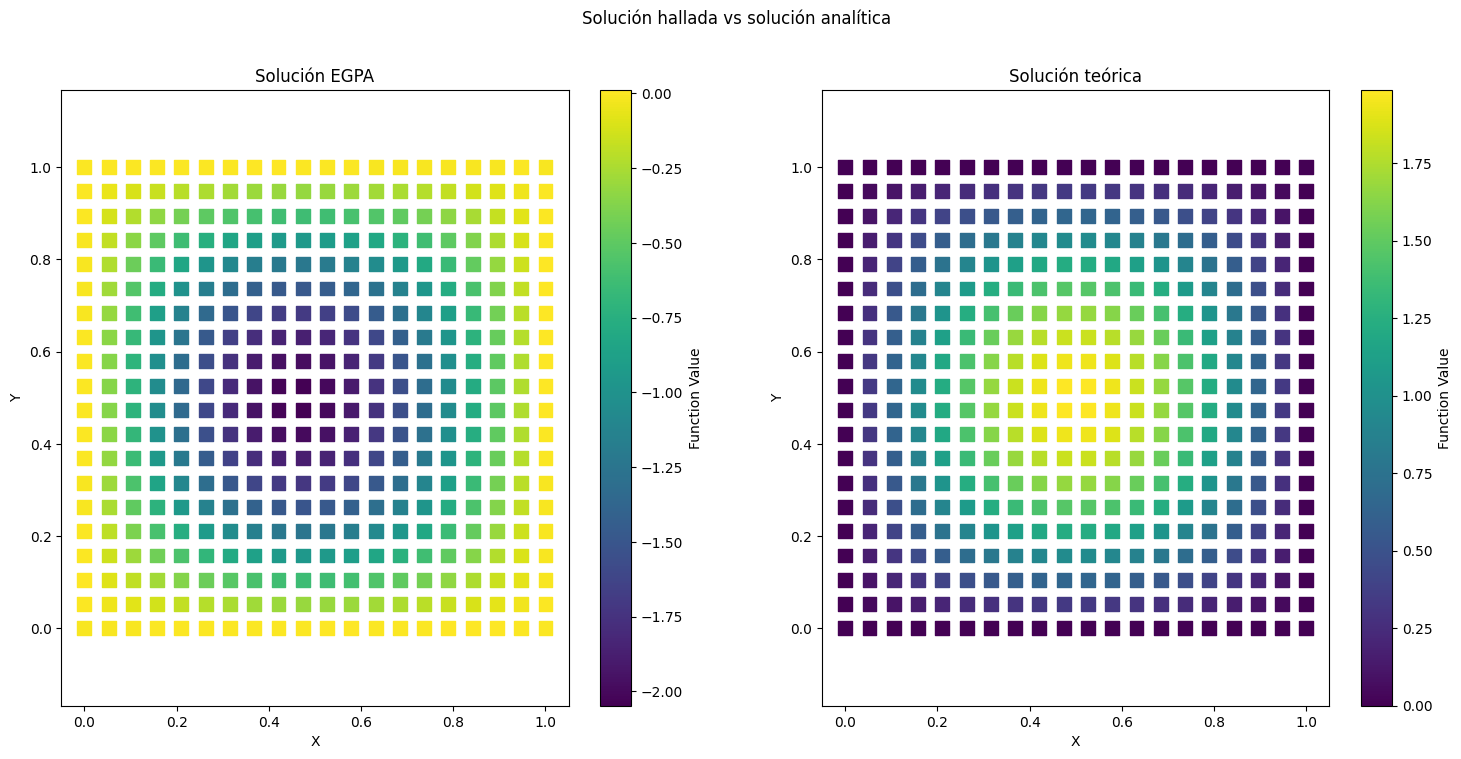

In [8]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle('Solución hallada vs solución analítica')

# First plot
sc1 = ax1.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=egparesultground.data[-1, :-1, 0], s=100, marker='s')
ax1.set_title("Solución EGPA")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.axis('equal')
cbar1 = fig.colorbar(sc1, ax=ax1)
cbar1.set_label("Function Value")

# Second plot
sc2 = ax2.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THPsi0flat, s=100, marker='s')
ax2.set_title("Solución teórica")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.axis('equal')
cbar2 = fig.colorbar(sc2, ax=ax2)
cbar2.set_label("Function Value")

In [9]:
mins = []
indices = []  # Store corresponding (i, indivs) pairs

for i in range(len(egparesultground.data)):
    for indivs in range(egparesultground.data.shape[2]):
        val = min([
            np.mean((egparesultground.data[i, :-1, indivs] - THPsi0flat)**2),
            np.mean((-1 * egparesultground.data[i, :-1, indivs] - THPsi0flat)**2)
        ])
        mins.append(val)
        indices.append((i, indivs))

# Find the index of the absolute minimum in mins
min_index = np.argmin(mins)
best_i, best_indivs = indices[min_index]

print(f"Minimum value is at i={best_i}, indivs={best_indivs}, with value {mins[min_index]}")


Minimum value is at i=0, indivs=0, with value 0.0049281149753109335


In [10]:
Estado = np.reshape(egparesultground.data[-1, :-1, 0], (len(egparesultground.data[-1, :-1, 0]), 1))
Psi0= reconvert_points_from_cartesian_stack_to_2D(Estado, x=x, y=y)
E0 = EnergyBox(Psi0, dx=dx, dy=dy)
MSE0 = min((np.mean((egparesultground.data[-1, :-1, 0] - THPsi0flat)**2),
            np.mean((-1*egparesultground.data[-1, :-1, 0] - THPsi0flat)**2)))
print(f'La energía del estado 1,1 teórica es: {Enxny(1,1)},\nEGPA encuentra energía: {E0},\ncon un error respecto de la solución teórica discretizada MSE= {MSE0}')

La energía del estado 1,1 teórica es: 9.869604401089358,
EGPA encuentra energía: 9.88900022971089,
con un error respecto de la solución teórica discretizada MSE= 0.0049281149753109335


In [11]:
print(f'La energía del estado es:{np.sqrt(egparesultground.data[-1, -1, 0])}, valor teórico Int función TH discretizada: {EnergyBox(THPsi0, dx=dx, dy=dy)}, con fórmula: {Enxny(1,1)}')

La energía del estado es:9.88900022971089, valor teórico Int función TH discretizada: 9.779987873035443, con fórmula: 9.869604401089358


In [12]:
#El proceso gaussiano último es:
GPprediction = egparesultground.GP_hist.predict(GPstack)
print(GPprediction.shape)
Estado = np.reshape(GPprediction, (len(GPprediction), 1))
GPPsi0= reconvert_points_from_cartesian_stack_to_2D(Estado, x=GPx, y=GPy)
NGPPsi0 = Normalize(GPPsi0, dx=dGPx, dy=dGPy)
GPE0 = EnergyBox(GPPsi0, dx=dGPx, dy=dGPy)
NGPE0 = EnergyBox(NGPPsi0, dx=dGPx, dy=dGPy)
GPMSE0 = min((np.mean((GPprediction - GPTHPsi0flat)**2),
            np.mean((-1*GPprediction - GPTHPsi0flat)**2)))
NGPMSE0 = min((np.mean((NGPPsi0 - GPTHPsi0)**2),
            np.mean((-1*NGPPsi0 - GPTHPsi0)**2)))

print(f'La energía del estado 1,1 teórica es: {Enxny(1,1)},\nGP entrenado por EGPA encuentra energía: {GPE0},\nGP entrenado por EGPA normalizado encuentra energía: {NGPE0},\ncon un error respecto de la solución teórica discretizada MSE= {GPMSE0}, \ncon un error respecto de la solución teórica discretizada Normalizado MSE= {NGPMSE0}')

(1024,)
La energía del estado 1,1 teórica es: 9.869604401089358,
GP entrenado por EGPA encuentra energía: 0.46248944747068904,
GP entrenado por EGPA normalizado encuentra energía: 11.584531302406935,
con un error respecto de la solución teórica discretizada MSE= 0.6091727508400546, 
con un error respecto de la solución teórica discretizada Normalizado MSE= 0.041332754251482196


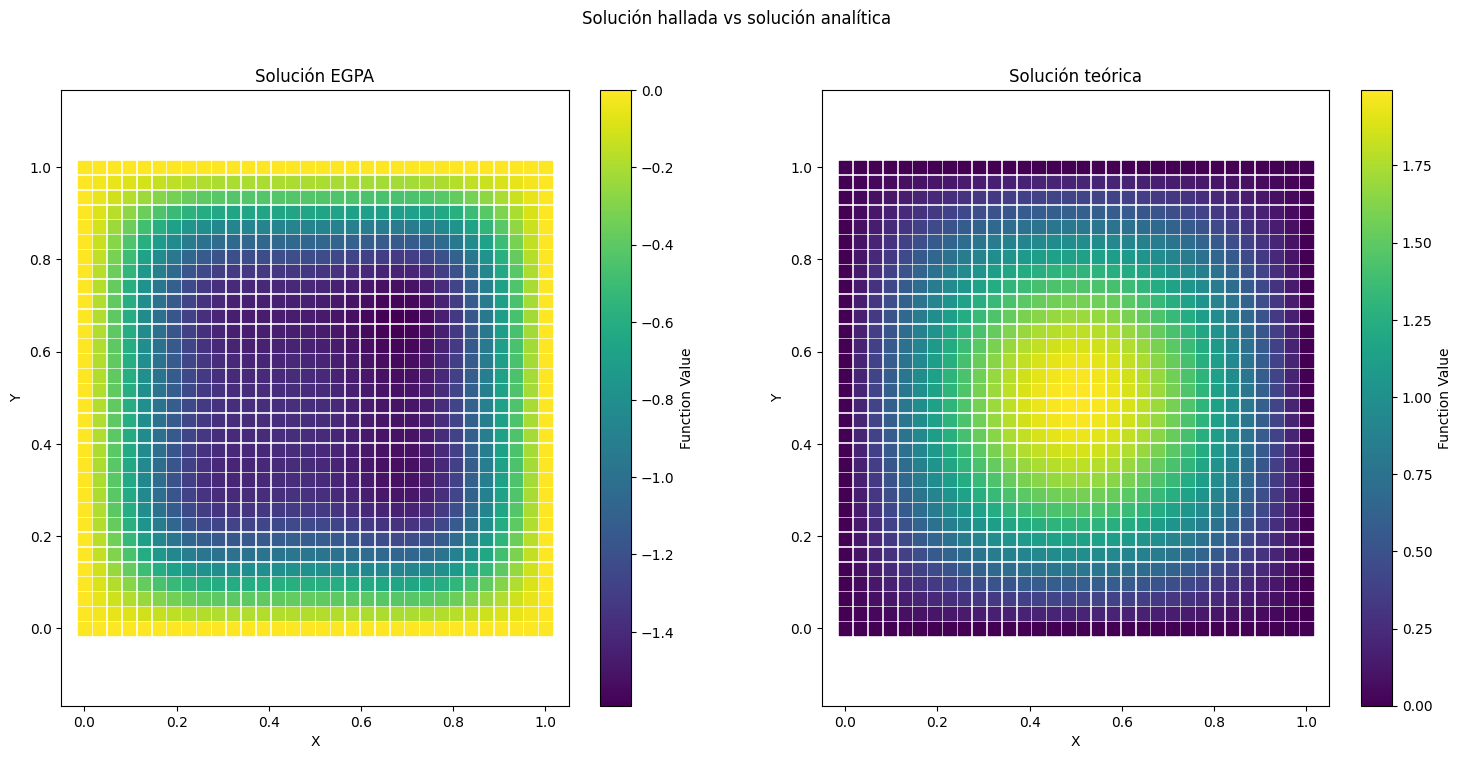

In [13]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle('Solución hallada vs solución analítica')

# First plot
sc1 = ax1.scatter(GPstack[:, 0], GPstack[:, 1], c=NGPPsi0.flatten(), s=80, marker='s')
ax1.set_title("Solución EGPA")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.axis('equal')
cbar1 = fig.colorbar(sc1, ax=ax1)
cbar1.set_label("Function Value")

# Second plot
sc2 = ax2.scatter(GPstack[:, 0], GPstack[:, 1], c=GPTHPsi0flat, s=80, marker='s')
ax2.set_title("Solución teórica")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.axis('equal')
cbar2 = fig.colorbar(sc2, ax=ax2)
cbar2.set_label("Function Value")

## Estado 1 2 o 2 1

In [14]:
params = {}
params['dx'] = dx
params['dy'] = dy
params['Psi0'] = Psi0
params['E0'] = E0
print(f'La Función de coste debe ser la diferencia de energías al cuadrado aprox\nCon fórmula: {(Enxny(1,2) - Enxny(1,1))**2}, con estado teórico discretizado: {(THE1integrando-THEintegrando)**2}')
print(f'Función de coste para energía teórica discreta F={TwoDBoxExc1(Psi=THPsi1, dx=dx, dy=dy, Psi0=Psi0, E0=E0)}')
while True:
    try: #values of alpha=0.01, elite = 0,006 with 1000 individuals
        Gaussian = TwoD_EGPA(size_gen=1000, grid_x=x, grid_y=y, max_iter=300, dead_iter=80, alpha=0.002, elite_factor=0.001, init_kernels=10, std_lower_bound=0.15 ,parallelize=True,init_data=init_data, normalize_solutions=True)
        egparesultexc1 = Gaussian.minimize(TwoDBoxExc1, params, exp_from = 420, output_runtime=True)
        if egparesultexc1.data[-1, -1, 0] >= 213.8: #antes 208.5
            continue
        else:
            break
    except:
        print('Error fiteando el Kernel. Reiniciando algoritmo...\n\n')
        continue

La Función de coste debe ser la diferencia de energías al cuadrado aprox
Con fórmula: 219.1704548265055, con estado teórico discretizado: 199.94172356378408
Función de coste para energía teórica discreta F=201.54314113625176
IT:  0 	Best cost:  208.11103864997526
IT:  1 	Best cost:  208.11103864997526
IT:  2 	Best cost:  208.11103864997526
IT:  3 	Best cost:  208.11103864997526
IT:  4 	Best cost:  208.11103864997526
IT:  5 	Best cost:  207.2435096288443
IT:  6 	Best cost:  207.2435096288443
IT:  7 	Best cost:  207.2435096288443
IT:  8 	Best cost:  207.2435096288443
IT:  9 	Best cost:  206.85175988559743
IT:  10 	Best cost:  206.85175988559743
IT:  11 	Best cost:  206.85175988559743
IT:  12 	Best cost:  206.85175988559743
IT:  13 	Best cost:  206.85175988559743
IT:  14 	Best cost:  206.85175988559743
IT:  15 	Best cost:  206.85175988559743
IT:  16 	Best cost:  206.85175988559743
IT:  17 	Best cost:  206.85175988559743
IT:  18 	Best cost:  206.85175988559743
IT:  19 	Best cost:  206.8517

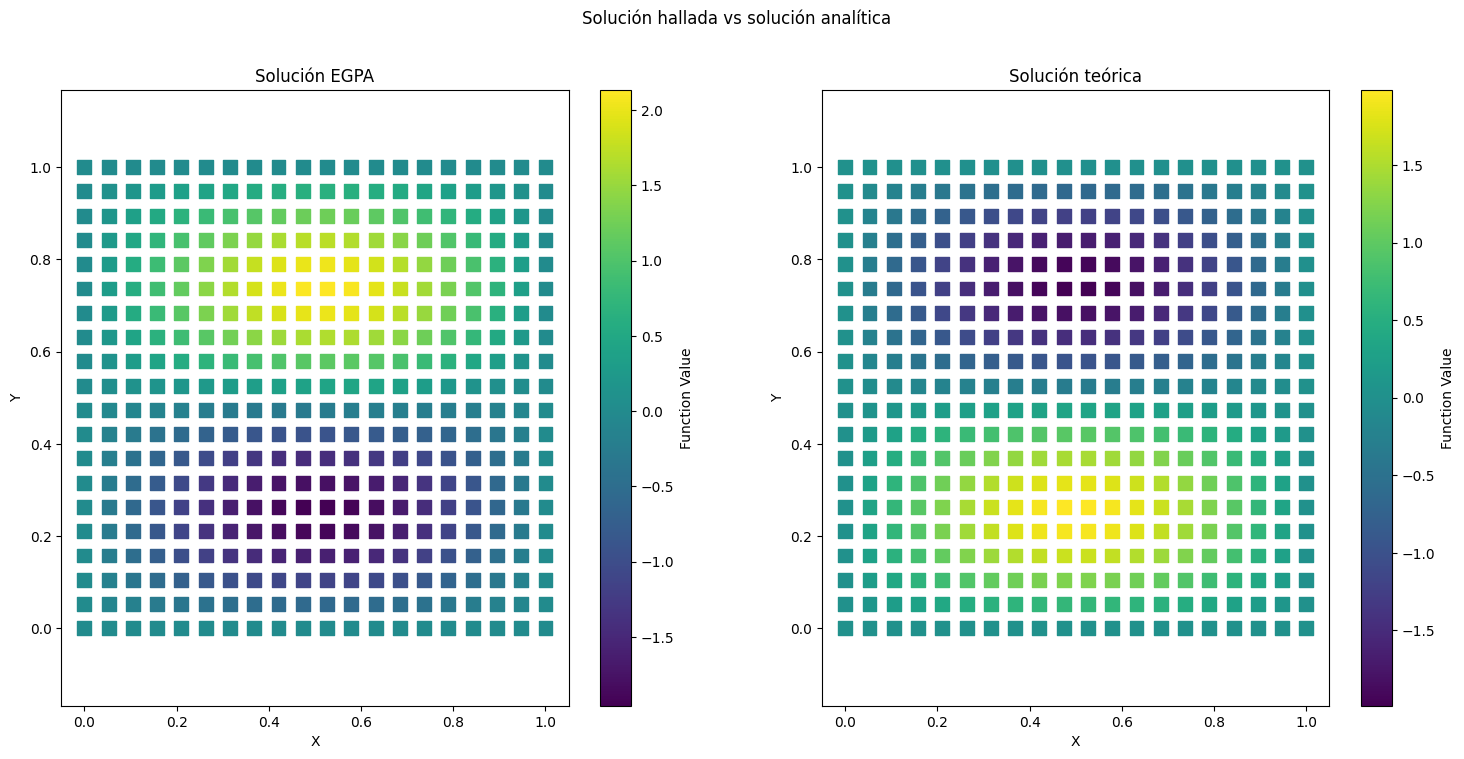

In [15]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle('Solución hallada vs solución analítica')

# First plot
sc1 = ax1.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=egparesultexc1.data[-1, :-1, 0], s=100, marker='s')
ax1.set_title("Solución EGPA")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.axis('equal')
cbar1 = fig.colorbar(sc1, ax=ax1)
cbar1.set_label("Function Value")

# Second plot
sc2 = ax2.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THPsi1flat, s=100, marker='s')
ax2.set_title("Solución teórica")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.axis('equal')
cbar2 = fig.colorbar(sc2, ax=ax2)
cbar2.set_label("Function Value")

In [16]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
    fig.suptitle('Solución hallada vs solución analítica')

    # First plot
    sc1 = ax1.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=egparesultexc1.data[i, :-1, 0], s=100, marker='s')
    ax1.set_title("Solución EGPA")
    ax1.set_xlabel("X")
    ax1.set_ylabel("Y")
    ax1.axis('equal')
    cbar1 = fig.colorbar(sc1, ax=ax1)
    cbar1.set_label("Function Value")

    # Second plot
    sc2 = ax2.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THPsi1flat, s=100, marker='s')
    ax2.set_title("Solución teórica")
    ax2.set_xlabel("X")
    ax2.set_ylabel("Y")
    ax2.axis('equal')
    cbar2 = fig.colorbar(sc2, ax=ax2)
    cbar2.set_label("Function Value")

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultexc1.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=162), Outp…

In [17]:
mins = []
for i in range(len(egparesultexc1.data)):
    for indivs in range(egparesultexc1.data.shape[2]):
        mins.append(min([np.mean((egparesultexc1.data[i, :-1, indivs] - THPsi1flat)**2),
                np.mean((-1*egparesultexc1.data[i, :-1, indivs] - THPsi1flat)**2),
                np.mean((egparesultexc1.data[i, :-1, indivs] - THPsi12flat)**2),
                np.mean((-1*egparesultexc1.data[i, :-1, indivs] - THPsi12flat)**2)]))
# for i in range(len(egparesultexc1.data)*egparesultexc1.data.shape[2]):
#     if mins[i]==min(mins):
#         print(i)
min(mins)

np.float64(0.0035990581903708914)

In [18]:
mins = []
indices = []  # Store corresponding (i, indivs) pairs

for i in range(len(egparesultexc1.data)):
    for indivs in range(egparesultexc1.data.shape[2]):
        val = min([
            np.mean((egparesultexc1.data[i, :-1, indivs] - THPsi1flat)**2),
            np.mean((-1 * egparesultexc1.data[i, :-1, indivs] - THPsi1flat)**2),
            np.mean((egparesultexc1.data[i, :-1, indivs] - THPsi12flat)**2),
            np.mean((-1 * egparesultexc1.data[i, :-1, indivs] - THPsi12flat)**2)
        ])
        mins.append(val)
        indices.append((i, indivs))

# Find the index of the absolute minimum in mins
min_index = np.argmin(mins)
best_i, best_indivs = indices[min_index]

print(f"Minimum value is at i={best_i}, indivs={best_indivs}, with value {mins[min_index]}")


Minimum value is at i=81, indivs=0, with value 0.0035990581903708914


In [19]:
print('Sin corchete:', min(np.mean((egparesultexc1.data[-1, :-1, 0] - THPsi1flat)**2),
            np.mean((-1*egparesultexc1.data[-1, :-1, 0] - THPsi1flat)**2),
            np.mean((egparesultexc1.data[-1, :-1, 0] - THPsi12flat)**2),
            np.mean((-1*egparesultexc1.data[-1, :-1, 0] - THPsi12flat)**2)),'\nCon corchete:',  min([np.mean((egparesultexc1.data[-1, :-1, 0] - THPsi1flat)**2),
            np.mean((-1*egparesultexc1.data[-1, :-1, 0] - THPsi1flat)**2),
            np.mean((egparesultexc1.data[-1, :-1, 0] - THPsi12flat)**2),
            np.mean((-1*egparesultexc1.data[-1, :-1, 0] - THPsi12flat)**2)]))

Sin corchete: 0.003773381664698727 
Con corchete: 0.003773381664698727


In [20]:
Estado = np.reshape(egparesultexc1.data[-1, :-1, 0], (len(egparesultexc1.data[-1, :-1, 0]), 1))
Psi1= reconvert_points_from_cartesian_stack_to_2D(Estado, x=x, y=y)
E1 = EnergyBox(Psi1, dx=dx, dy=dy)
MSE1 = min(np.mean((egparesultexc1.data[-1, :-1, 0] - THPsi1flat)**2),
            np.mean((-1*egparesultexc1.data[-1, :-1, 0] - THPsi1flat)**2),
            np.mean((egparesultexc1.data[-1, :-1, 0] - THPsi12flat)**2),
            np.mean((-1*egparesultexc1.data[-1, :-1, 0] - THPsi12flat)**2))
print(f'La energía del estado 1,2 teórica es: {Enxny(2,1)},\nEGPA encuentra energía: {E1},\ncon un error respecto de la solución teórica discretizada MSE= {MSE1}')

La energía del estado 1,2 teórica es: 24.674011002723397,
EGPA encuentra energía: 24.007267794779317,
con un error respecto de la solución teórica discretizada MSE= 0.003773381664698727


In [21]:
print(f'La energía del estado es:{np.sqrt(egparesultexc1.data[-1, -1, 0])+E0}, valor teórico Int función TH discretizada: {EnergyBox(THPsi1, dx=dx, dy=dy)}, con fórmula: {Enxny(1,2)}')

La energía del estado es:24.091228587023586, valor teórico Int función TH discretizada: 23.920062963493205, con fórmula: 24.674011002723397


In [22]:
#El proceso gaussiano último es:
GPprediction = egparesultexc1.GP_hist.predict(GPstack)
print(GPprediction.shape)
Estado = np.reshape(GPprediction, (len(GPprediction), 1))
GPPsi1= reconvert_points_from_cartesian_stack_to_2D(Estado, x=GPx, y=GPy)
NGPPsi1 = Normalize(GPPsi1, dx=dGPx, dy=dGPy)
GPE1 = EnergyBox(GPPsi1, dx=dGPx, dy=dGPy)
NGPE1 = EnergyBox(NGPPsi1, dx=dGPx, dy=dGPy)
GPMSE1 = min((np.mean((GPprediction - GPTHPsi1flat)**2),
            np.mean((-1*GPprediction - GPTHPsi1flat)**2)))
NGPMSE1 = min((np.mean((NGPPsi1 - GPTHPsi1)**2),
            np.mean((-1*NGPPsi1 - GPTHPsi1)**2)))

print(f'La energía del estado 1,2 teórica es: {Enxny(1,1)},\nGP entrenado por EGPA encuentra energía: {GPE1},\nGP entrenado por EGPA normalizado encuentra energía: {NGPE1},\ncon un error respecto de la solución teórica discretizada MSE= {GPMSE1}, \ncon un error respecto de la solución teórica discretizada Normalizado MSE= {NGPMSE1}')

(1024,)
La energía del estado 1,2 teórica es: 9.869604401089358,
GP entrenado por EGPA encuentra energía: 20.95789130921837,
GP entrenado por EGPA normalizado encuentra energía: 24.82865335532633,
con un error respecto de la solución teórica discretizada MSE= 0.01401283567420457, 
con un error respecto de la solución teórica discretizada Normalizado MSE= 0.008508713459491007


# Estado ortogonal al 1 2 o 2 1 

In [23]:
params = {}
params['dx'] = dx
params['dy'] = dy
params['Psi0'] = Psi0
params['E0'] = E0
params['Psi1'] = Psi1
params['E1'] = E1
import warnings
warnings.filterwarnings('ignore')

print(f'La Función de coste debe ser la diferencia de energías al cuadrado aprox\nCon fórmula: {(Enxny(1,2) - Enxny(1,1))**2}, con estado teórico discretizado: {(THE1integrando-THEintegrando)**2}')
print(f'Función de coste para energía teórica discreta F={TwoDBoxExc12(Psi=THPsi12, dx=dx, dy=dy, Psi0=THPsi0, E0=E0, Psi1=THPsi1, E1=E1)}')

while True:
    try:
        Gaussian = TwoD_EGPA(size_gen=1000, grid_x=x, grid_y=y, max_iter=250, dead_iter=80, alpha=0.01, elite_factor=0.006, init_kernels=10, std_lower_bound=0.1 ,parallelize=True,init_data=init_data, normalize_solutions=True)
        egparesultexc12 = Gaussian.minimize(TwoDBoxExc12, params, exp_from = 420, output_runtime=True)
        break
    except:
        print('Error fiteando el Kernel. Reiniciando algoritmo...\n\n')
        continue

La Función de coste debe ser la diferencia de energías al cuadrado aprox
Con fórmula: 219.1704548265055, con estado teórico discretizado: 199.94172356378408
Función de coste para energía teórica discreta F=196.87072143933335
IT:  0 	Best cost:  312.2488767993708
IT:  1 	Best cost:  312.2488767993708
IT:  2 	Best cost:  312.2488767993708
IT:  3 	Best cost:  312.2488767993708
IT:  4 	Best cost:  312.2488767993708
IT:  5 	Best cost:  312.2488767993708
IT:  6 	Best cost:  312.2488767993708
IT:  7 	Best cost:  312.2488767993708
IT:  8 	Best cost:  312.2488767993708
IT:  9 	Best cost:  312.2488767993708
IT:  10 	Best cost:  312.2488767993708
IT:  11 	Best cost:  312.2488767993708
IT:  12 	Best cost:  312.2488767993708
IT:  13 	Best cost:  312.2488767993708
IT:  14 	Best cost:  312.2488767993708
IT:  15 	Best cost:  312.2488767993708
IT:  16 	Best cost:  312.2488767993708
IT:  17 	Best cost:  312.2488767993708
IT:  18 	Best cost:  312.2488767993708
IT:  19 	Best cost:  312.2488767993708
IT:  

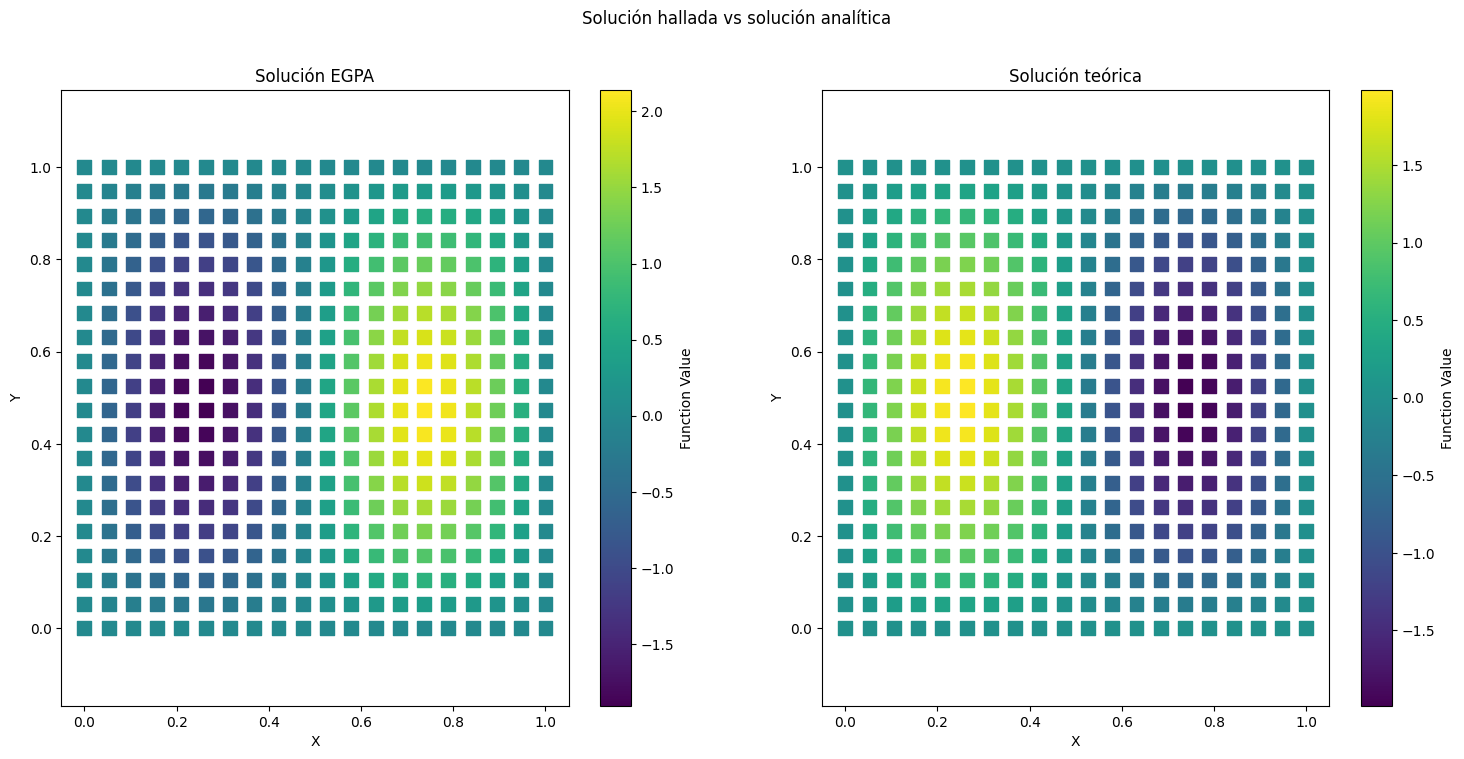

In [24]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle('Solución hallada vs solución analítica')

# First plot
sc1 = ax1.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=egparesultexc12.data[-1, :-1, 0], s=100, marker='s')
ax1.set_title("Solución EGPA")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.axis('equal')
cbar1 = fig.colorbar(sc1, ax=ax1)
cbar1.set_label("Function Value")

# Second plot
sc2 = ax2.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THPsi12flat, s=100, marker='s')
ax2.set_title("Solución teórica")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.axis('equal')
cbar2 = fig.colorbar(sc2, ax=ax2)
cbar2.set_label("Function Value")

In [25]:
mins = []
indices = []  # Store corresponding (i, indivs) pairs

for i in range(len(egparesultexc12.data)):
    for indivs in range(egparesultexc12.data.shape[2]):
        val = min([
            np.mean((egparesultexc12.data[i, :-1, indivs] - THPsi1flat)**2),
            np.mean((-1 * egparesultexc12.data[i, :-1, indivs] - THPsi1flat)**2),
            np.mean((egparesultexc12.data[i, :-1, indivs] - THPsi12flat)**2),
            np.mean((-1 * egparesultexc12.data[i, :-1, indivs] - THPsi12flat)**2)
        ])
        mins.append(val)
        indices.append((i, indivs))

# Find the index of the absolute minimum in mins
min_index = np.argmin(mins)
best_i, best_indivs = indices[min_index]

print(f"Minimum value is at i={best_i}, indivs={best_indivs}, with value {mins[min_index]}")


Minimum value is at i=247, indivs=0, with value 0.00597481122817747


In [26]:
#El proceso gaussiano último es:
GPprediction = egparesultexc12.GP_hist.predict(GPstack)
print(GPprediction.shape)
Estado = np.reshape(GPprediction, (len(GPprediction), 1))
GPPsi12= reconvert_points_from_cartesian_stack_to_2D(Estado, x=GPx, y=GPy)
NGPPsi12 = Normalize(GPPsi12, dx=dGPx, dy=dGPy)
GPE12 = EnergyBox(GPPsi12, dx=dGPx, dy=dGPy)
NGPE12 = EnergyBox(NGPPsi12, dx=dGPx, dy=dGPy)
GPMSE12 = min((np.mean((GPprediction - GPTHPsi12flat)**2),
            np.mean((-1*GPprediction - GPTHPsi12flat)**2)))
NGPMSE12 = min((np.mean((NGPPsi12 - GPTHPsi12)**2),
            np.mean((-1*NGPPsi12 - GPTHPsi12)**2)))

print(f'La energía del estado 1,2 teórica es: {Enxny(1,2)},\nGP entrenado por EGPA encuentra energía: {GPE12},\nGP entrenado por EGPA normalizado encuentra energía: {NGPE12},\ncon un error respecto de la solución teórica discretizada MSE= {GPMSE12}, \ncon un error respecto de la solución teórica discretizada Normalizado MSE= {NGPMSE12}')

(1024,)
La energía del estado 1,2 teórica es: 24.674011002723397,
GP entrenado por EGPA encuentra energía: 22.713519622720735,
GP entrenado por EGPA normalizado encuentra energía: 24.59185557505486,
con un error respecto de la solución teórica discretizada MSE= 0.010061437409685091, 
con un error respecto de la solución teórica discretizada Normalizado MSE= 0.00898783136137457


In [27]:
Estado = np.reshape(egparesultexc12.data[-1, :-1, 0], (len(egparesultexc12.data[-1, :-1, 0]), 1))
Psi12= reconvert_points_from_cartesian_stack_to_2D(Estado, x=x, y=y)
E12 = EnergyBox(Psi12, dx=dx, dy=dy)
MSE12 = min(np.mean((egparesultexc12.data[-1, :-1, 0] - THPsi1flat)**2),
            np.mean((-1*egparesultexc12.data[-1, :-1, 0] - THPsi1flat)**2),
            np.mean((egparesultexc12.data[-1, :-1, 0] - THPsi12flat)**2),
            np.mean((-1*egparesultexc12.data[-1, :-1, 0] - THPsi12flat)**2))
print(f'La energía del estado 1,2 teórica es: {Enxny(2,1)},\nEGPA encuentra energía: {E12},\ncon un error respecto de la solución teórica discretizada MSE= {MSE12}')

La energía del estado 1,2 teórica es: 24.674011002723397,
EGPA encuentra energía: 23.890927069728342,
con un error respecto de la solución teórica discretizada MSE= 0.00597481122817747


In [28]:
print(f'La energía del estado es:{np.sqrt(egparesultexc12.data[-1, -1, 0])+E0}, valor teórico Int función TH discretizada: {EnergyBox(THPsi12, dx=dx, dy=dy)}, con fórmula: {Enxny(1,2)}')

La energía del estado es:23.89618924393617, valor teórico Int función TH discretizada: 23.920062963493205, con fórmula: 24.674011002723397


# Estado 2 2

In [29]:
params = {}
params['dx'] = dx
params['dy'] = dy
params['Psi0'] = Psi0
params['E0'] = E0
params['Psi1'] = Psi1
params['E1'] = E1
params['Psi12'] = Psi12
params['E12'] = E12

print(f'La función de coste tiene que ser la diferencia de energías al cuadrado {(EnergyBox(Psi=THPsi2, dx=dx,dy=dy) - EnergyBox(Psi=THPsi1, dx=dx,dy=dy))**2}')
print(f'Función de coste para energía teórica discreta F={TwoDBoxExc2(Psi=THPsi2, dx=dx, dy=dy, Psi0=Psi0, E0=E0, Psi1=Psi1, E1=E1, Psi12=Psi12, E12=E12)}')

while True:
    try:
        Gaussian = TwoD_EGPA(size_gen=1000, grid_x=x, grid_y=y, max_iter=380, dead_iter=60, alpha=0.002, elite_factor=0.001, init_kernels=10, std_lower_bound=0.1 ,parallelize=True,init_data=init_data, normalize_solutions=True)
        egparesultexc2 = Gaussian.minimize(TwoDBoxExc2, params, exp_from = 403, output_runtime=True)
        break
    except:
        print('Error fiteando el Kernel. Reiniciando algoritmo...\n\n')
        continue

La función de coste tiene que ser la diferencia de energías al cuadrado 199.94172356378402
Función de coste para energía teórica discreta F=209.24293444973947


IT:  0 	Best cost:  1603.0214974298756
IT:  1 	Best cost:  1192.0871733731958
IT:  2 	Best cost:  621.185012827777
IT:  3 	Best cost:  556.0336995587287
IT:  4 	Best cost:  520.8899505911423
IT:  5 	Best cost:  457.6532249312169
IT:  6 	Best cost:  411.6809302041381
IT:  7 	Best cost:  376.00811070780213
IT:  8 	Best cost:  367.65449593620383
IT:  9 	Best cost:  329.79471992188354
IT:  10 	Best cost:  313.83458076915423
IT:  11 	Best cost:  287.44510986937763
IT:  12 	Best cost:  281.3897661931866
IT:  13 	Best cost:  274.3918733443543
IT:  14 	Best cost:  266.78582678614566
IT:  15 	Best cost:  262.9210187778723
IT:  16 	Best cost:  241.88964880356752
IT:  17 	Best cost:  235.6039670301431
IT:  18 	Best cost:  234.01720457423053
IT:  19 	Best cost:  234.01720457423053
IT:  20 	Best cost:  234.01720457423053
IT:  21 	Best cost:  234.01720457423053
IT:  22 	Best cost:  229.48421480529072
IT:  23 	Best cost:  224.41394646827317
IT:  24 	Best cost:  222.88632776372867
IT:  25 	Best cost: 

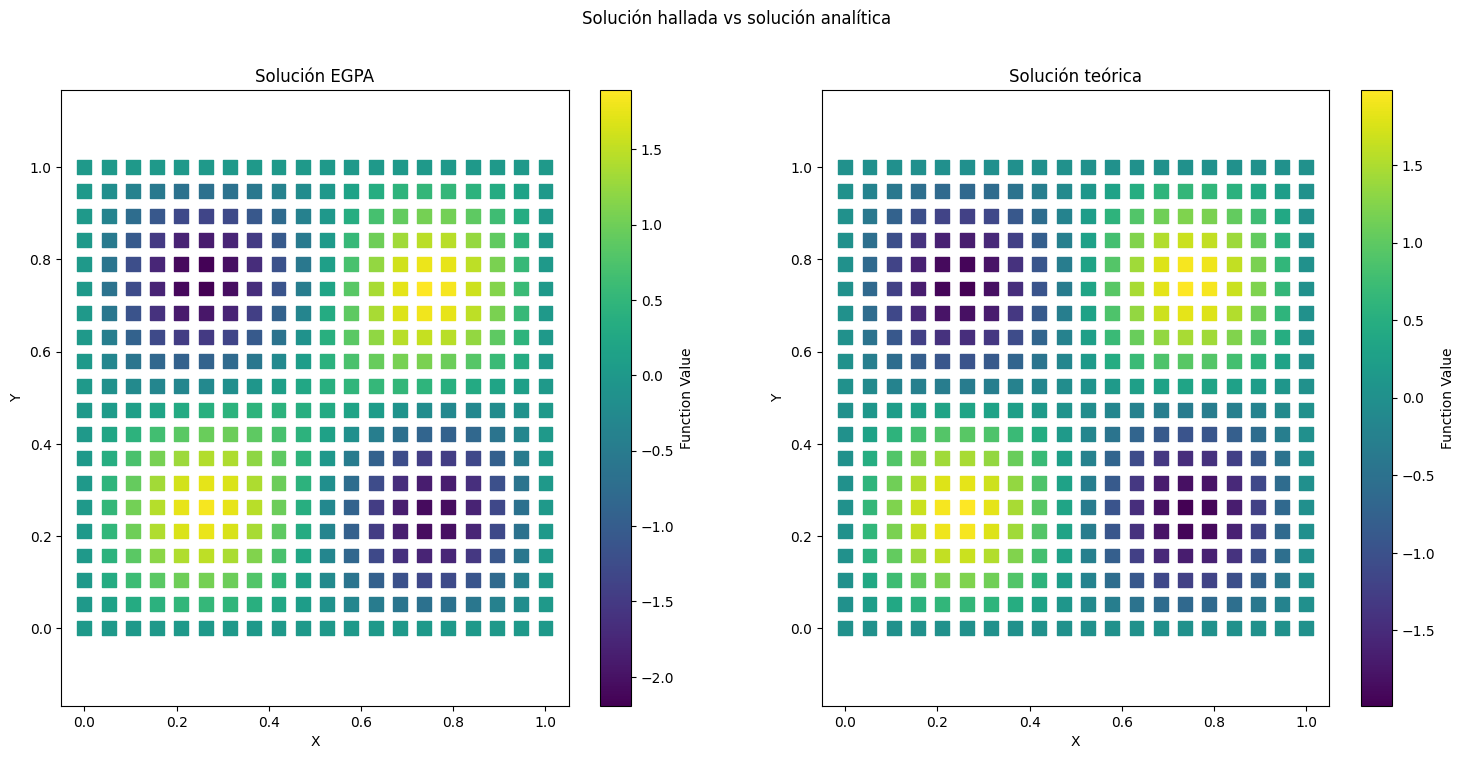

In [30]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
fig.suptitle('Solución hallada vs solución analítica')

# First plot
sc1 = ax1.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=egparesultexc2.data[-1, :-1, 0], s=100, marker='s')
ax1.set_title("Solución EGPA")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.axis('equal')
cbar1 = fig.colorbar(sc1, ax=ax1)
cbar1.set_label("Function Value")

# Second plot
sc2 = ax2.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THPsi2flat, s=100, marker='s')
ax2.set_title("Solución teórica")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.axis('equal')
cbar2 = fig.colorbar(sc2, ax=ax2)
cbar2.set_label("Function Value")

AttributeError: 'numpy.ndarray' object has no attribute 'set_xlim'

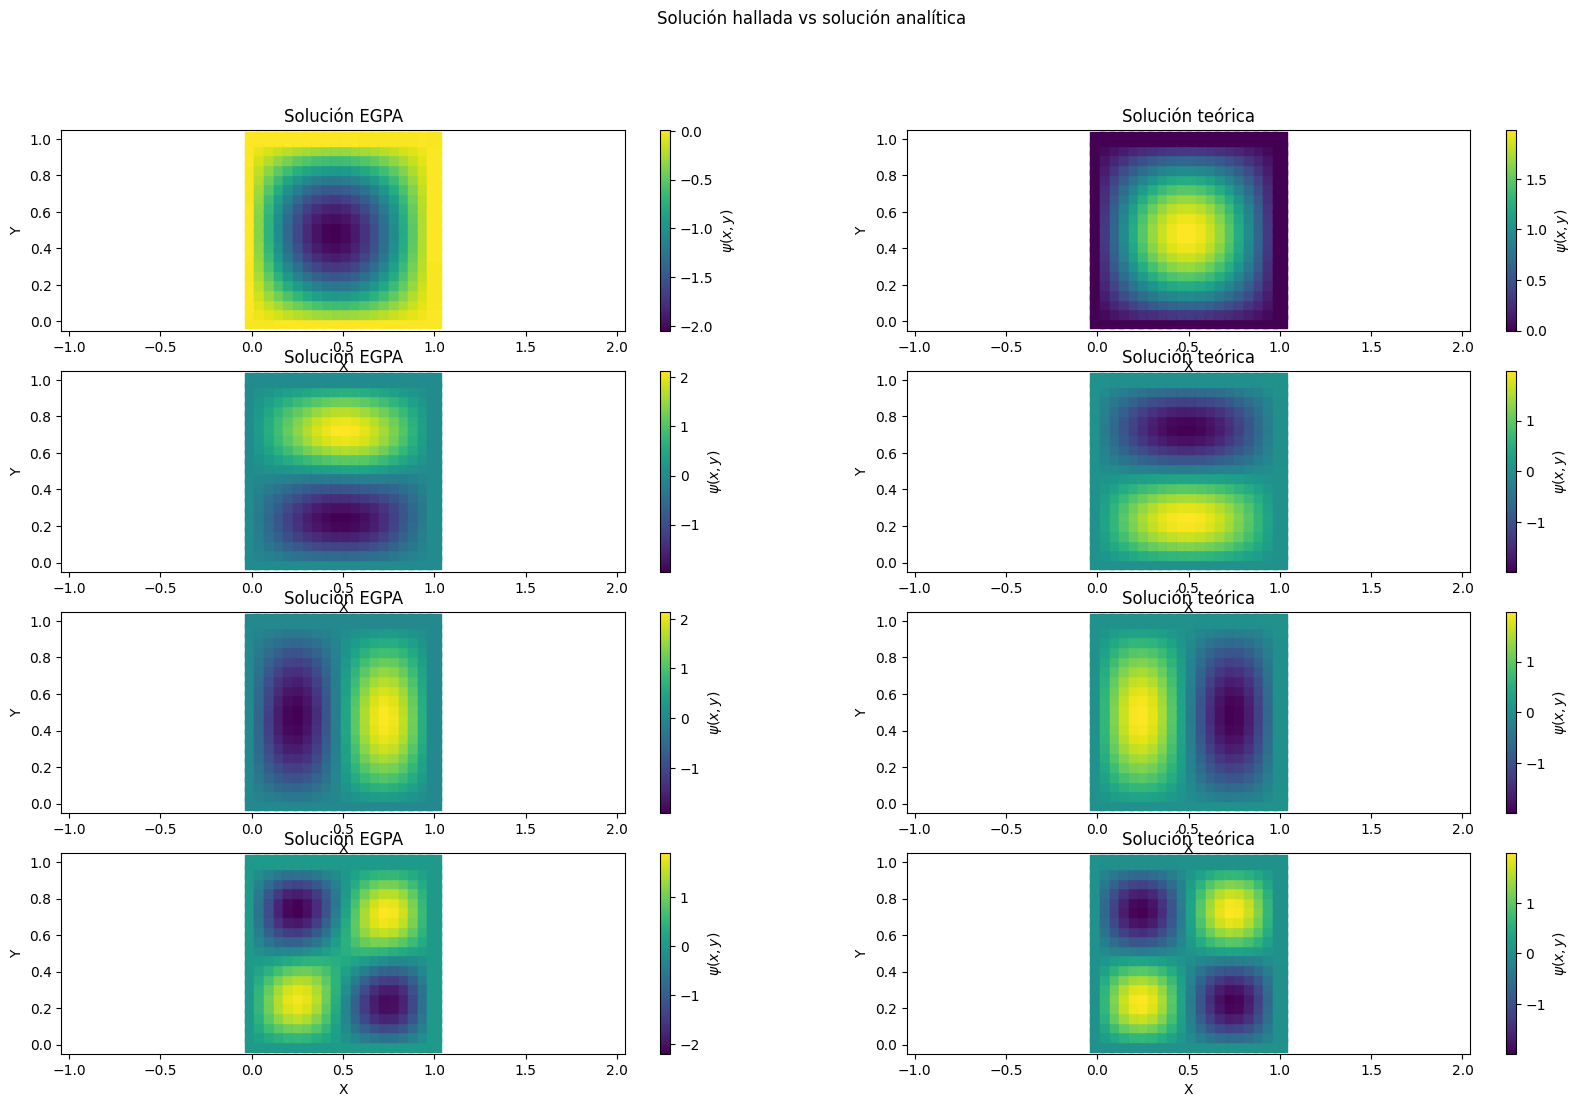

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 2, figsize=(20, 12))
ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8 = axes.ravel()

fig.suptitle('Solución hallada vs solución analítica')

# First plot
sc1 = ax1.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=egparesultground.data[-1, :-1, 0], s=100, marker='s')
ax1.set_title("Solución EGPA")
ax1.set_xlabel("X")
ax1.set_ylabel("Y")
ax1.axis('equal')
fig.colorbar(sc1, ax=ax1).set_label(r"$\psi(x, y)$")

# Second plot
sc2 = ax2.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THPsi0flat, s=100, marker='s')
ax2.set_title("Solución teórica")
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.axis('equal')
fig.colorbar(sc2, ax=ax2).set_label(r"$\psi(x, y)$")

# Repeat for the rest
sc3 = ax3.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=egparesultexc1.data[-1, :-1, 0], s=100, marker='s')
ax3.set_title("Solución EGPA")
ax3.set_xlabel("X")
ax3.set_ylabel("Y")
ax3.axis('equal')
fig.colorbar(sc3, ax=ax3).set_label(r"$\psi(x, y)$")

sc4 = ax4.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THPsi1flat, s=100, marker='s')
ax4.set_title("Solución teórica")
ax4.set_xlabel("X")
ax4.set_ylabel("Y")
ax4.axis('equal')
fig.colorbar(sc4, ax=ax4).set_label(r"$\psi(x, y)$")

sc5 = ax5.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=egparesultexc12.data[-1, :-1, 0], s=100, marker='s')
ax5.set_title("Solución EGPA")
ax5.set_xlabel("X")
ax5.set_ylabel("Y")
ax5.axis('equal')
fig.colorbar(sc5, ax=ax5).set_label(r"$\psi(x, y)$")

sc6 = ax6.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THPsi12flat, s=100, marker='s')
ax6.set_title("Solución teórica")
ax6.set_xlabel("X")
ax6.set_ylabel("Y")
ax6.axis('equal')
fig.colorbar(sc6, ax=ax6).set_label(r"$\psi(x, y)$")

sc7 = ax7.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=egparesultexc2.data[-1, :-1, 0], s=100, marker='s')
ax7.set_title("Solución EGPA")
ax7.set_xlabel("X")
ax7.set_ylabel("Y")
ax7.axis('equal')
fig.colorbar(sc7, ax=ax7).set_label(r"$\psi(x, y)$")

sc8 = ax8.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THPsi2flat, s=100, marker='s')
ax8.set_title("Solución teórica")
ax8.set_xlabel("X")
ax8.set_ylabel("Y")
ax8.axis('equal')
fig.colorbar(sc8, ax=ax8).set_label(r"$\psi(x, y)$")

plt.tight_layout()
plt.show()


In [ ]:
import pickle
niceresultados = {}
niceresultados['egparesultground'] = egparesultground
niceresultados['egparesultexc1'] = egparesultexc1
niceresultados['egparesultexc12'] = egparesultexc12
niceresultados['egparesultexc2'] = egparesultexc2

ruta = 'EGPA2D_results/2DBoxniceresults'
with open(f'{ruta}.pkl', "wb") as file:
    pickle.dump(niceresultados, file)

## To load nice results and change figures for paper if needed:
# with open(f'{ruta}.pkl', "rb") as file:
#     niceresultados = pickle.load(file)
# egparesultground = niceresultados['egparesultground']
# egparesultexc1 = niceresultados['egparesultexc1']
# egparesultexc12 = niceresultados['egparesultexc12']
# egparesultexc2 = niceresultados['egparesultexc2'] 

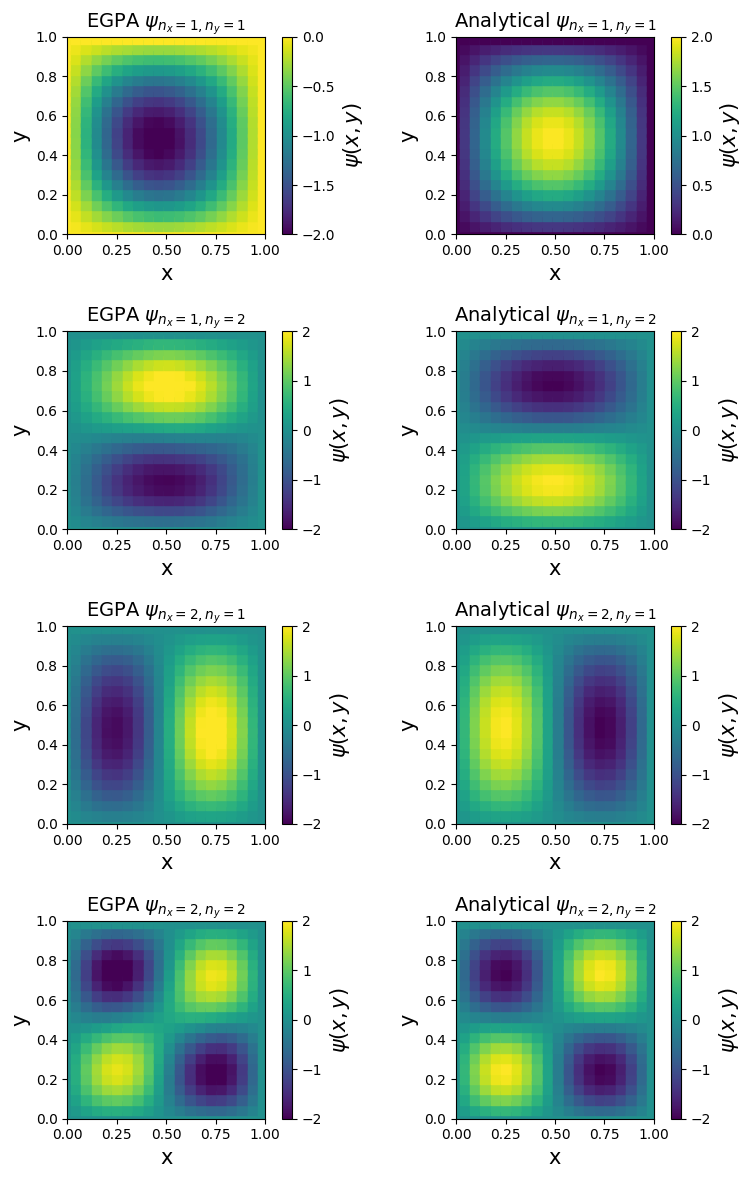

In [103]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 2, figsize=(8, 12))
ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8 = axes.ravel()

#fig.suptitle('2D Quantum Box\nEGPA solutions                   Analytical solutions')

# Reduce spacing between columns
plt.subplots_adjust(wspace=0, hspace=0.4)  # smaller wspace gives closer columns

# Larger global font settings
plt.rcParams.update({
    'font.size': 14,         # base font size
    'axes.titlesize': 14,    # subplot titles
    'axes.labelsize': 15,    # axis labels
    'xtick.labelsize': 10,   # x-axis tick labels
    'ytick.labelsize': 10,   # y-axis tick labels
    'figure.titlesize': 18   # main title
})

plots_data = [
    (ax1, -1*egparesultground.data[-1, :-1, 0], r"EGPA $\psi_{n_x=1, n_y=1}$"), #(x, y)$
    (ax2, THPsi0flat, r"Analytical $\psi_{n_x=1, n_y=1}$"),
    (ax3, egparesultexc1.data[-1, :-1, 0], r"EGPA $\psi_{n_x=1, n_y=2}$"),
    (ax4, THPsi1flat, r"Analytical $\psi_{n_x=1, n_y=2}$"),
    (ax5, egparesultexc12.data[-1, :-1, 0], r"EGPA $\psi_{n_x=2, n_y=1}$"),
    (ax6, THPsi12flat, r"Analytical $\psi_{n_x=2, n_y=1}$"),
    (ax7, egparesultexc2.data[-1, :-1, 0], r"EGPA $\psi_{n_x=2, n_y=2}$"),
    (ax8, THPsi2flat, r"Analytical $\psi_{n_x=2, n_y=2}$")
]

for ax, cdata, title in plots_data:
    if ax==ax1:
        sc = ax.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=-1*cdata, s=100, marker='s', vmin=-2, vmax=0)
    
    elif ax==ax2:
        sc = ax.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=cdata, s=100, marker='s', vmin=0, vmax=2)

    else:
        sc = ax.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=cdata, s=100, marker='s', vmin=-2, vmax=2)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks((0, 0.25, 0.5, 0.75, 1))
    ax.set_aspect('equal', adjustable='box')
    fig.colorbar(sc, ax=ax).set_label(r"$\psi(x, y)$")

plt.tight_layout()
plt.savefig('EGPA2D_results/2DBox.pdf', format='pdf')
plt.show()


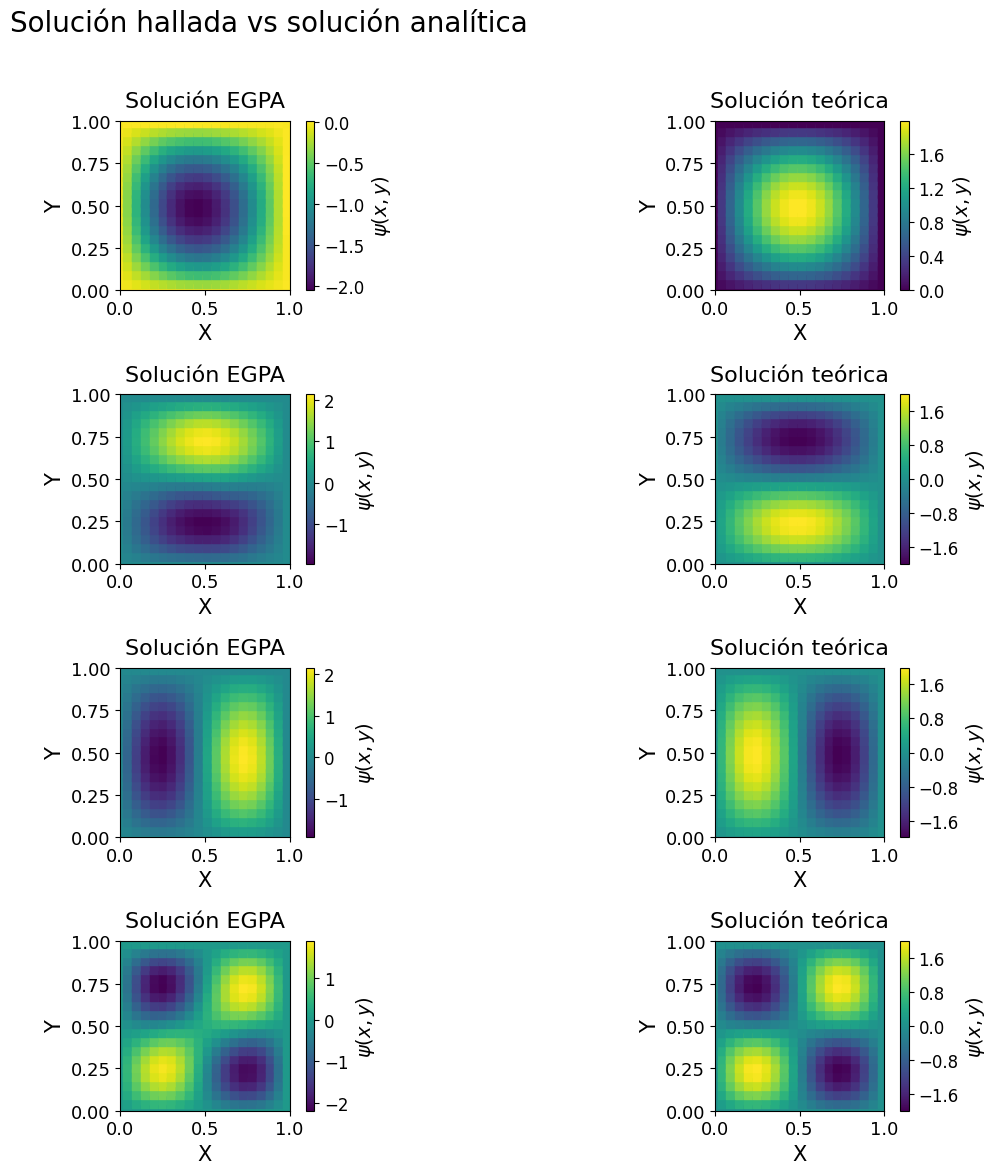

In [50]:
import matplotlib.pyplot as plt

# Create figure and axes
fig, axes = plt.subplots(4, 2, figsize=(15, 12))

# Reduce spacing between columns
plt.subplots_adjust(wspace=0.001, hspace=0.4)  # smaller wspace gives closer columns

# Larger global font settings
plt.rcParams.update({
    'font.size': 14,         # base font size
    'axes.titlesize': 16,    # subplot titles
    'axes.labelsize': 15,    # axis labels
    'xtick.labelsize': 13,   # x-axis tick labels
    'ytick.labelsize': 13,   # y-axis tick labels
    'figure.titlesize': 18   # main title
})

# Flatten axes safely
axes = axes.ravel()
fig.suptitle('Solución hallada vs solución analítica', fontsize=20)

plots_data = [
    (axes[0], egparesultground.data[-1, :-1, 0], "Solución EGPA"),
    (axes[1], THPsi0flat, "Solución teórica"),
    (axes[2], egparesultexc1.data[-1, :-1, 0], "Solución EGPA"),
    (axes[3], THPsi1flat, "Solución teórica"),
    (axes[4], egparesultexc12.data[-1, :-1, 0], "Solución EGPA"),
    (axes[5], THPsi12flat, "Solución teórica"),
    (axes[6], egparesultexc2.data[-1, :-1, 0], "Solución EGPA"),
    (axes[7], THPsi2flat, "Solución teórica")
]

for ax, cdata, title in plots_data:
    sc = ax.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=cdata, s=80, marker='s')  # a bit smaller markers
    ax.set_title(title, pad=10)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal', adjustable='box')

    # Add a nicely formatted colorbar
    cbar = fig.colorbar(sc, ax=ax, pad=0.02, fraction=0.046)
    cbar.set_label(r"$\psi(x, y)$", fontsize=14)
    cbar.ax.tick_params(labelsize=12)

    # Attempt to make ticks more regular automatically
    cbar.locator = plt.MaxNLocator(5)  # Aim for 5 evenly spaced ticks
    cbar.update_ticks()

plt.tight_layout(rect=[0, 0, 1, 0.97])  # leave space for title
plt.show()


In [31]:
mins = []
indices = []  # Store corresponding (i, indivs) pairs

for i in range(len(egparesultexc2.data)):
    for indivs in range(egparesultexc2.data.shape[2]):
        val = min([
            np.mean((egparesultexc2.data[i, :-1, indivs] - THPsi2flat)**2),
            np.mean((-1 * egparesultexc2.data[i, :-1, indivs] - THPsi2flat)**2)
        ])
        mins.append(val)
        indices.append((i, indivs))

# Find the index of the absolute minimum in mins
min_index = np.argmin(mins)
best_i, best_indivs = indices[min_index]

print(f"Minimum value is at i={best_i}, indivs={best_indivs}, with value {mins[min_index]}")


Minimum value is at i=336, indivs=0, with value 0.0285511159075339


In [32]:
Estado = np.reshape(egparesultexc2.data[-1, :-1, 0], (len(egparesultexc2.data[-1, :-1, 0]), 1))
Psi2= reconvert_points_from_cartesian_stack_to_2D(Estado, x=x, y=y)
E2 = EnergyBox(Psi2, dx=dx, dy=dy)
MSE2 = min(np.mean((egparesultexc2.data[-1, :-1, 0] - THPsi2flat)**2),
            np.mean((-1*egparesultexc2.data[-1, :-1, 0] - THPsi2flat)**2))
print(f'La energía del estado 2,2 teórica es: {Enxny(2,2)},\nEGPA encuentra energía: {E2},\ncon un error respecto de la solución teórica discretizada MSE= {MSE2}')

La energía del estado 2,2 teórica es: 39.47841760435743,
EGPA encuentra energía: 38.32619826860884,
con un error respecto de la solución teórica discretizada MSE= 0.02904744587327811


In [33]:
from IPython.display import clear_output
import time
import ipywidgets as widgets
from ipywidgets import interact

# Function to update the plot based on the selected generation
def update_plot(i):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
    fig.suptitle('Solución hallada vs solución analítica')

    # First plot
    sc1 = ax1.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=egparesultexc2.data[i, :-1, 0], s=100, marker='s')
    ax1.set_title("Solución EGPA")
    ax1.set_xlabel("X")
    ax1.set_ylabel("Y")
    ax1.axis('equal')
    cbar1 = fig.colorbar(sc1, ax=ax1)
    cbar1.set_label("Function Value")

    # Second plot
    sc2 = ax2.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THPsi2flat, s=100, marker='s')
    ax2.set_title("Solución teórica")
    ax2.set_xlabel("X")
    ax2.set_ylabel("Y")
    ax2.axis('equal')
    cbar2 = fig.colorbar(sc2, ax=ax2)
    cbar2.set_label("Function Value")

#Create a slider widget
generation_slider = widgets.IntSlider(value=0, min=0, max=len(egparesultexc2.data)-1, step=1, description='Generation', layout=widgets.Layout(width='100%'))

# Use interact to connect the slider with the update_plot function
interact(update_plot, i=generation_slider);


interactive(children=(IntSlider(value=0, description='Generation', layout=Layout(width='100%'), max=379), Outp…

In [54]:
#El proceso gaussiano último es:
GPprediction = egparesultexc2.GP_hist.predict(GPstack)
print(GPprediction.shape)
Estado = np.reshape(GPprediction, (len(GPprediction), 1))
GPPsi2= reconvert_points_from_cartesian_stack_to_2D(Estado, x=GPx, y=GPy)
NGPPsi2 = Normalize(GPPsi2, dx=dGPx, dy=dGPy)
GPE2 = EnergyBox(GPPsi2, dx=dGPx, dy=dGPy)
NGPE2 = EnergyBox(NGPPsi2, dx=dGPx, dy=dGPy)
GPMSE2 = min((np.mean((GPprediction - GPTHPsi2flat)**2),
            np.mean((-1*GPprediction - GPTHPsi2flat)**2)))
NGPMSE2 = min((np.mean((NGPPsi2 - GPTHPsi2)**2),
            np.mean((-1*NGPPsi2 - GPTHPsi2)**2)))

print(f'La energía del estado 2,2 teórica es: {Enxny(2,2)},\nGP entrenado por EGPA encuentra energía: {GPE2},\nGP entrenado por EGPA normalizado encuentra energía: {NGPE2},\ncon un error respecto de la solución teórica discretizada MSE= {GPMSE2}, \ncon un error respecto de la solución teórica discretizada Normalizado MSE= {NGPMSE2}')

(1024,)
La energía del estado 2,2 teórica es: 39.47841760435743,
GP entrenado por EGPA encuentra energía: 34.84520677618419,
GP entrenado por EGPA normalizado encuentra energía: 39.58032844528175,
con un error respecto de la solución teórica discretizada MSE= 0.032227158732557805, 
con un error respecto de la solución teórica discretizada Normalizado MSE= 0.030536778446857156


# Estado 3 1 o 1 3

In [35]:
# params = {}
# params['dx'] = dx
# params['dy'] = dy
# params['Psi0'] = Psi0
# params['E0'] = E0
# params['Psi1'] = Psi1
# params['E1'] = E1
# params['Psi12'] = Psi12
# params['E12'] = E12
# params['Psi2'] = Psi2
# params['E2'] = E2

# print(f'La función de coste tiene que ser la diferencia de energías al cuadrado {(EnergyBox(Psi=THPsi3, dx=dx,dy=dy) - EnergyBox(Psi=THPsi2, dx=dx,dy=dy))**2}')
# print(f'Función de coste para energía teórica discreta F={TwoDBoxExc3(Psi=THPsi3, dx=dx, dy=dy, Psi0=THPsi0, E0=E0, Psi1=THPsi1, E1=E1, Psi12=THPsi12, E12=E12, Psi2=THPsi2, E2=E2)}')

# while True:
#     try:
#         Gaussian = TwoD_EGPA(size_gen=1000, grid_x=x, grid_y=y, max_iter=380, dead_iter=80, alpha=0.01, elite_factor=0.006, init_kernels=10, std_lower_bound=0.1 ,parallelize=True,init_data=init_data, normalize_solutions=True)
#         egparesultexc3 = Gaussian.minimize(TwoDBoxExc3, params, exp_from = 403, output_runtime=True)
#         break
#     except:
#         print('Error fiteando el Kernel. Reiniciando algoritmo...\n\n')
#         continue

In [36]:
# import matplotlib.pyplot as plt

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
# fig.suptitle('Solución hallada vs solución analítica')

# # First plot
# sc1 = ax1.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=egparesultexc3.data[-1, :-1, 0], s=100, marker='s')
# ax1.set_title("Solución EGPA")
# ax1.set_xlabel("X")
# ax1.set_ylabel("Y")
# ax1.axis('equal')
# cbar1 = fig.colorbar(sc1, ax=ax1)
# cbar1.set_label("Function Value")

# # Second plot
# sc2 = ax2.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THPsi3flat, s=100, marker='s')
# ax2.set_title("Solución teórica")
# ax2.set_xlabel("X")
# ax2.set_ylabel("Y")
# ax2.axis('equal')
# cbar2 = fig.colorbar(sc2, ax=ax2)
# cbar2.set_label("Function Value")

In [37]:
# mins = []
# indices = []  # Store corresponding (i, indivs) pairs

# for i in range(len(egparesultexc3.data)):
#     for indivs in range(egparesultexc3.data.shape[2]):
#         val = min([
#             np.mean((egparesultexc3.data[i, :-1, indivs] - THPsi3flat)**2),
#             np.mean((-1 * egparesultexc3.data[i, :-1, indivs] - THPsi3flat)**2),
#             np.mean((egparesultexc3.data[i, :-1, indivs] - THPsi31flat)**2),
#             np.mean((-1 * egparesultexc3.data[i, :-1, indivs] - THPsi31flat)**2)
#         ])
#         mins.append(val)
#         indices.append((i, indivs))

# # Find the index of the absolute minimum in mins
# min_index = np.argmin(mins)
# best_i, best_indivs = indices[min_index]

# print(f"Minimum value is at i={best_i}, indivs={best_indivs}, with value {mins[min_index]}")


In [38]:
# Estado = np.reshape(egparesultexc3.data[-1, :-1, 0], (len(egparesultexc3.data[-1, :-1, 0]), 1))
# Psi3= reconvert_points_from_cartesian_stack_to_2D(Estado, x=x, y=y)
# E3 = EnergyBox(Psi3, dx=dx, dy=dy)
# MSE3 = min(np.mean((egparesultexc3.data[-1, :-1, 0] - THPsi3flat)**2),
#             np.mean((-1*egparesultexc3.data[-1, :-1, 0] - THPsi3flat)**2),
#             np.mean((egparesultexc3.data[-1, :-1, 0] - THPsi31flat)**2),
#             np.mean((-1*egparesultexc3.data[-1, :-1, 0] - THPsi31flat)**2))
# print(f'La energía del estado 31 teórica es: {Enxny(3,1)},\nEGPA encuentra energía: {E3},\ncon un error respecto de la solución teórica discretizada MSE= {MSE3}')

## Estado ortogonal al 31 o 13

In [39]:
# params = {}
# params['dx'] = dx
# params['dy'] = dy
# params['Psi0'] = Psi0
# params['E0'] = E0
# params['Psi1'] = Psi1
# params['E1'] = E1
# params['Psi12'] = Psi12
# params['E12'] = E12
# params['Psi2'] = Psi2
# params['E2'] = E2
# params['Psi3'] = Psi3
# params['E3'] = E3

# print(f'La función de coste tiene que ser la diferencia de energías al cuadrado {(EnergyBox(Psi=THPsi3, dx=dx,dy=dy) - EnergyBox(Psi=THPsi2, dx=dx,dy=dy))**2}')
# print(f'Función de coste para energía teórica discreta F={TwoDBoxExc31(Psi=THPsi31, dx=dx, dy=dy, Psi0=Psi0, E0=E0, Psi1=Psi1, E1=E1, Psi12=Psi12, E12=E12, Psi2=Psi2, E2=E2, Psi3=THPsi3, E3=E3)}')


# while True:
#     try:
#         Gaussian = TwoD_EGPA(size_gen=1000, grid_x=x, grid_y=y, max_iter=380, dead_iter=80, alpha=0.01, elite_factor=0.006, init_kernels=10, std_lower_bound=0.1 ,parallelize=True,init_data=init_data, normalize_solutions=True)
#         egparesultexc31 = Gaussian.minimize(TwoDBoxExc31, params, exp_from = 403, output_runtime=True)
#         break
#     except:
#         print('Error fiteando el Kernel. Reiniciando algoritmo...\n\n')
#         continue

In [40]:
# import matplotlib.pyplot as plt

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
# fig.suptitle('Solución hallada vs solución analítica')

# # First plot
# sc1 = ax1.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=egparesultexc31.data[-1, :-1, 0], s=100, marker='s')
# ax1.set_title("Solución EGPA")
# ax1.set_xlabel("X")
# ax1.set_ylabel("Y")
# ax1.axis('equal')
# cbar1 = fig.colorbar(sc1, ax=ax1)
# cbar1.set_label("Function Value")

# # Second plot
# sc2 = ax2.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THPsi3flat, s=100, marker='s')
# ax2.set_title("Solución teórica")
# ax2.set_xlabel("X")
# ax2.set_ylabel("Y")
# ax2.axis('equal')
# cbar2 = fig.colorbar(sc2, ax=ax2)
# cbar2.set_label("Function Value")

In [41]:
# mins = []
# indices = []  # Store corresponding (i, indivs) pairs

# for i in range(len(egparesultexc31.data)):
#     for indivs in range(egparesultexc31.data.shape[2]):
#         val = min([
#             np.mean((egparesultexc31.data[i, :-1, indivs] - THPsi3flat)**2),
#             np.mean((-1 * egparesultexc31.data[i, :-1, indivs] - THPsi3flat)**2),
#             np.mean((egparesultexc31.data[i, :-1, indivs] - THPsi31flat)**2),
#             np.mean((-1 * egparesultexc31.data[i, :-1, indivs] - THPsi31flat)**2)
#         ])
#         mins.append(val)
#         indices.append((i, indivs))

# # Find the index of the absolute minimum in mins
# min_index = np.argmin(mins)
# best_i, best_indivs = indices[min_index]

# print(f"Minimum value is at i={best_i}, indivs={best_indivs}, with value {mins[min_index]}")


In [42]:
# Estado = np.reshape(egparesultexc31.data[-1, :-1, 0], (len(egparesultexc31.data[-1, :-1, 0]), 1))
# Psi31= reconvert_points_from_cartesian_stack_to_2D(Estado, x=x, y=y)
# E31 = EnergyBox(Psi31, dx=dx, dy=dy)
# MSE31 = min(np.mean((egparesultexc31.data[-1, :-1, 0] - THPsi3flat)**2),
#             np.mean((-1*egparesultexc31.data[-1, :-1, 0] - THPsi3flat)**2),
#             np.mean((egparesultexc31.data[-1, :-1, 0] - THPsi31flat)**2),
#             np.mean((-1*egparesultexc31.data[-1, :-1, 0] - THPsi31flat)**2),)
# print(f'La energía del estado 3,1 teórica es: {Enxny(3,1)},\nEGPA encuentra energía: {E31},\ncon un error respecto de la solución teórica discretizada MSE= {MSE31}')

## Obtención de métricas. MSE y error en energía.

In [43]:
# MSEs = []
# for i in range(4):
#     mse = np.mean((params[f'Psi{i}'] - APsis[f'APsi{i}'])**2)
#     MSEs.append(mse)

In [44]:
# import pandas as pd
# d = {'Psi': [f'Psi{i}' for i in range(4)], 'MSE': MSEs, 'E': [ 0.5+i for i in range(4)], 'E_calc': E_calc, 't_exc': t}
# df = pd.DataFrame(data=d)
# df = df.reset_index(drop=True)
# df

In [45]:
# import pickle
# results_dict = {}
# objects = ['egparesultground', 'egparesultexc1', 'egparesultexc2']
# results_dict['egparesultground'] = egparesultground
# results_dict['egparesultexc1'] = egparesultexc1
# results_dict['egparesultexc2'] = egparesultexc2
# ruta = 'Results'
# with open(f'{ruta}.pkl', "wb") as file:
#     pickle.dump(results_dict, file)


In [46]:
# import pickle
# ruta = 'Results'
# with open(f'{ruta}.pkl', "rb") as file:
#     results_dict = pickle.load(file)

In [47]:
# egparesultground = results_dict['egparesultground'] 
# egparesultexc1 = results_dict['egparesultexc1'] 
# egparesultexc2 = results_dict['egparesultexc2'] 

### Prubeas para comprobar ortogonalidad de estados

Dado el estado nx=1, ny=2, en su forma de matriz $\Psi_{ij} = \Psi(x_i, y_j)$ se cumple que (el estado traspuesto) $\Psi^T_{nx=1\,ny=2}  = \Psi _{nx=2\,ny=1}$ con las mismas energías integrando.

¿Are these states orthogonal?
Yes, los estados $\Psi_{nx=1\,ny=2}  = \Psi _{nx=2\,ny=1}$ son ortogonales

¿Es $\Psi_{nx=1\,ny=2}$ ortogonal con $-\Psi_{nx=1\,ny=2}$? No, su 'producto vectorial' ($\int<\Psi_{nx=1\,ny=2}|-\Psi_{nx=1\,ny=2}>$) sale -1 que va al cuadrado en función de coste (1)

In [48]:
# THPsi1flat, THPsi1, THE1integrando = Psinxny(1,2,x=x, y=y, dx=dx, dy=dy)
# THotraPsi1flat, THotraPsi1, THotraE1integrando = Psinxny(2,1,x=x, y=y, dx=dx, dy=dy)

In [49]:
# THE1integrando, THotraE1integrando

In [50]:
# THPsi1T = THPsi1.T.flatten()

In [51]:
# import matplotlib.pyplot as plt

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
# fig.suptitle('Solución hallada vs solución analítica')

# # First plot
# sc1 = ax1.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THotraPsi1flat, s=100, marker='s')
# ax1.set_title("Solución teórica nx=1, ny=2 ")
# ax1.set_xlabel("X")
# ax1.set_ylabel("Y")
# ax1.axis('equal')
# cbar1 = fig.colorbar(sc1, ax=ax1)
# cbar1.set_label("Function Value")

# # Second plot
# sc2 = ax2.scatter(Cartesianstack[:, 0], Cartesianstack[:, 1], c=THPsi1T, s=100, marker='s')
# ax2.set_title("Solución teórica nx=1, ny=2, traspuesta")
# ax2.set_xlabel("X")
# ax2.set_ylabel("Y")
# ax2.axis('equal')
# cbar2 = fig.colorbar(sc2, ax=ax2)
# cbar2.set_label("Function Value")

In [52]:
# def can_fill_surface(D1, D2, a, b):
#     # Verificar si el área es divisible
#     if (D1 * D2) % (a * b) != 0:
#         return False, "No es posible llenar la superficie exactamente."

#     # Verificar si alguna orientación encaja perfectamente
#     if (D1 % a == 0 and D2 % b == 0) or (D1 % b == 0 and D2 % a == 0):
#         return True, "Es posible llenar la superficie."

#     return False, "No se puede llenar exactamente con solo una orientación."

# # Ejemplo de uso:
# D1, D2 = 370, 220  # Dimensiones de la superficie
# a, b = 120, 80      # Dimensiones de las piezas

# result, message = can_fill_surface(D1, D2, a, b)
# print(message)

In [53]:
# from Box_functions import *
# def Psinxny(nx, ny, x, y):
#     L=1
#     Funcion = None
#     for i in x:
#         for j in y:
#             valor = 2/L*np.sin(nx*np.pi*i/L)*np.sin(ny*np.pi*j/L)
#             if Funcion is None:
#                 Funcion = valor
#             else:
#                 Funcion = np.append(Funcion, valor)
#     Estado = np.reshape(Funcion, (len(Funcion), 1))
#     Estado = reconvert_points_from_cartesian_stack_to_2D(SAMPLES=Estado, x=x, y=y)
#     return Funcion.flatten(), Estado
# def Enxny(nx, ny):
#     L=1
#     return np.pi**2/(2*L**2)*(nx**2+ny**2)   